In [2]:
from pathlib import Path
import json
import matplotlib.pyplot as plt

# Find a nonempty, valid regression notebook
candidates = [
    Path("regression_implementation.ipynb"),
    Path("notebooks/regression_implementation.ipynb"),
    Path("../regression_implementation.ipynb"),
]

source = None

for path in candidates:
    if path.is_file() and path.stat().st_size > 0:
        try:
            with path.open(encoding="utf-8") as f:
                notebook = json.load(f)

            if "cells" in notebook:
                source = path.resolve()
                break

        except json.JSONDecodeError:
            continue

if source is None:
    raise FileNotFoundError(
        "No valid regression notebook found. "
    )

print("Using notebook:", source)

# Run the regression notebook and import its variables
get_ipython().run_line_magic("run", f'"{source}"')

print("Experiments loaded:", list(results))


Using notebook: /Users/hammondutra/Developer/cs156-machine-learning/assignments/01_brawl_stars/src/regression_implementation.ipynb
Project root: /Users/hammondutra/Developer/cs156-machine-learning/assignments/01_brawl_stars
Available experiments:
['E0_prior', 'E1_original_signed', 'E2_augmented_signed', 'E3_original_separate', 'E4_brawl_only', 'E5_brawl_original']

--- Fold 1 ---
E0_prior: 34 test matches
E1_original_signed: 34 test matches
E2_augmented_signed: 34 test matches
E3_original_separate: 34 test matches
E4_brawl_only: 19 test matches
E5_brawl_original: 19 test matches

--- Fold 2 ---
E0_prior: 33 test matches
E1_original_signed: 33 test matches
E2_augmented_signed: 33 test matches
E3_original_separate: 33 test matches
E4_brawl_only: 19 test matches
E5_brawl_original: 19 test matches

--- Fold 3 ---
E0_prior: 33 test matches
E1_original_signed: 33 test matches
E2_augmented_signed: 33 test matches
E3_original_separate: 33 test matches
E4_brawl_only: 19 test matches
E5_brawl_or

In [3]:
# Calculate metrics using our existing evaluation function
scores = {
    name: evaluate(predictions)
    for name, predictions in results.items()
}

labels = {
    "E0_prior": "E0 - Baseline",
    "E1_original_signed": "E1 - Signed",
    "E2_augmented_signed": "E2 - Mirrored",
    "E3_original_separate": "E3 - Separate",
    "E4_brawl_only": "E4 - Brawl Ball Mirrored",
    "E5_brawl_original": "E5 - Brawl Ball Original"
}

print(f"{'Model':<20} {'Accuracy':>10} {'Bal.Acc':>10} {'Log Loss':>10} {'Brier':>10}")
print("-" * 65)

for name, s in scores.items():
    print(
        f"{labels[name]:<20} "
        f"{s['accuracy']:>10.3f} "
        f"{s['balanced_accuracy']:>10.3f} "
        f"{s['log_loss']:>10.3f} "
        f"{s['brier']:>10.3f}"
    )


Model                  Accuracy    Bal.Acc   Log Loss      Brier
-----------------------------------------------------------------
E0 - Baseline             0.747      0.500      0.566      0.189
E1 - Signed               0.722      0.516      0.576      0.192
E2 - Mirrored             0.611      0.554      0.638      0.224
E3 - Separate             0.747      0.532      0.584      0.196
E4 - Brawl Ball Mirrored      0.613      0.571      0.664      0.236
E5 - Brawl Ball Original      0.688      0.521      0.626      0.214


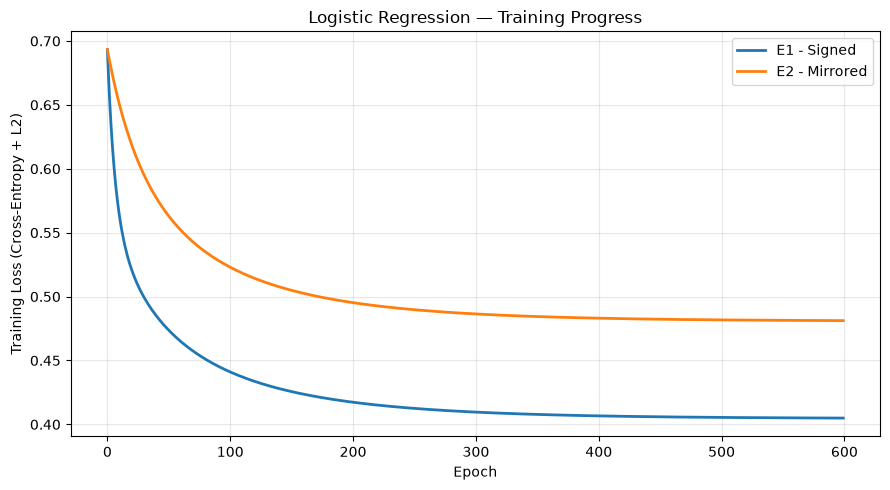

In [4]:
train, test = folds[0]
experiments = experiment_sets(train, test)

plt.figure(figsize=(9, 5))

for name in ["E1_original_signed", "E2_augmented_signed"]:

    data = experiments[name]

    model = train_logistic(
        data["X_train"],
        data["y_train"],
        learning_rate=0.3,
        epochs=600,
        l2=0.01
    )

    plt.plot(
        model["losses"],
        label=labels[name],
        linewidth=2
    )

plt.title("Logistic Regression — Training Progress")
plt.xlabel("Epoch")
plt.ylabel("Training Loss (Cross-Entropy + L2)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


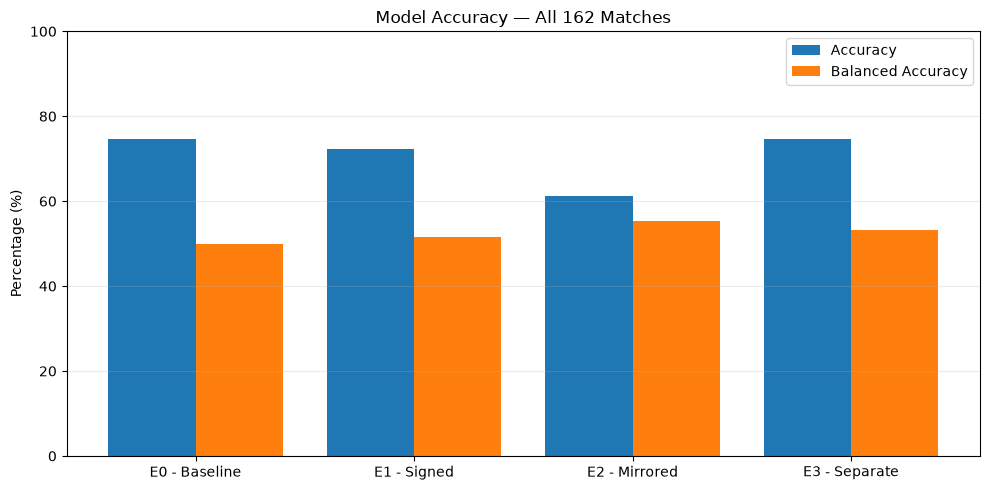

In [5]:

models = [
    "E0_prior",
    "E1_original_signed",
    "E2_augmented_signed",
    "E3_original_separate"
]

names = [labels[m] for m in models]
accuracy = [scores[m]["accuracy"] * 100 for m in models]
balanced = [scores[m]["balanced_accuracy"] * 100 for m in models]

x = range(len(models))

plt.figure(figsize=(10, 5))

plt.bar(
    [i - 0.2 for i in x],
    accuracy,
    width=0.4,
    label="Accuracy"
)

plt.bar(
    [i + 0.2 for i in x],
    balanced,
    width=0.4,
    label="Balanced Accuracy"
)

plt.xticks(list(x), names)
plt.ylabel("Percentage (%)")
plt.ylim(0, 100)
plt.title("Model Accuracy — All 162 Matches")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

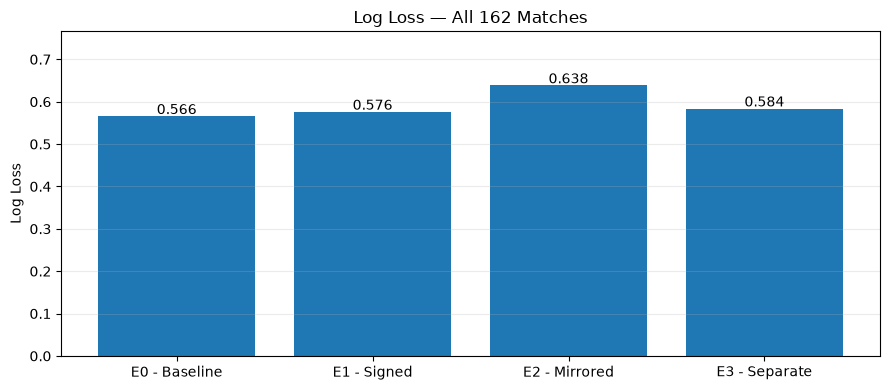

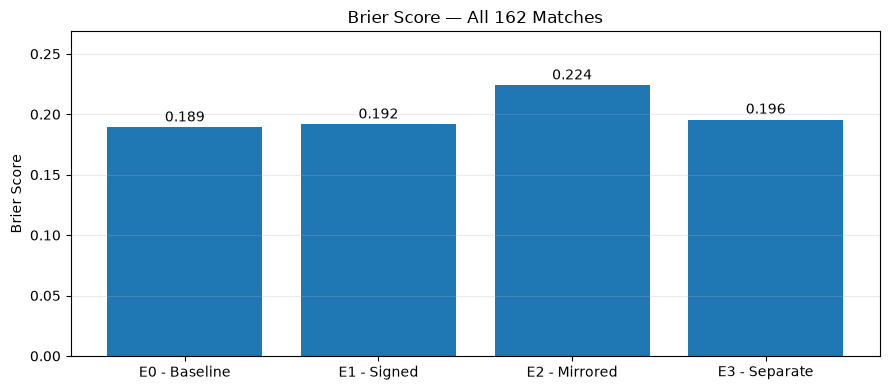

In [6]:
for metric, title in [
    ("log_loss", "Log Loss"),
    ("brier", "Brier Score")
]:
    values = [scores[m][metric] for m in models]

    plt.figure(figsize=(9, 4))
    bars = plt.bar(names, values)

    for bar, value in zip(bars, values):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.005,
            f"{value:.3f}",
            ha="center"
        )

    plt.title(f"{title} — All 162 Matches")
    plt.ylabel(title)
    plt.ylim(0, max(values) * 1.2)
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()


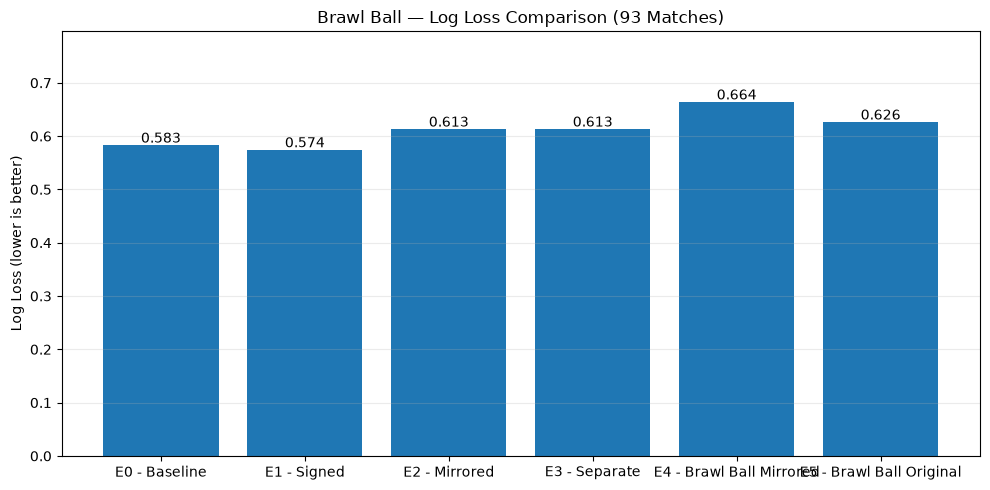

In [7]:
brawl_ids = {
    row["pair_id"]
    for row in results["E4_brawl_only"]
}

brawl_scores = {}

for name, predictions in results.items():

    subset = [
        row for row in predictions
        if row["pair_id"] in brawl_ids
    ]

    assert len(subset) == len(brawl_ids)

    brawl_scores[name] = evaluate(subset)

brawl_models = list(results.keys())
brawl_names = [labels[m] for m in brawl_models]
brawl_losses = [brawl_scores[m]["log_loss"] for m in brawl_models]

plt.figure(figsize=(10, 5))
bars = plt.bar(brawl_names, brawl_losses)

for bar, value in zip(bars, brawl_losses):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.005,
        f"{value:.3f}",
        ha="center"
    )

plt.title("Brawl Ball — Log Loss Comparison (93 Matches)")
plt.ylabel("Log Loss (lower is better)")
plt.ylim(0, max(brawl_losses) * 1.2)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


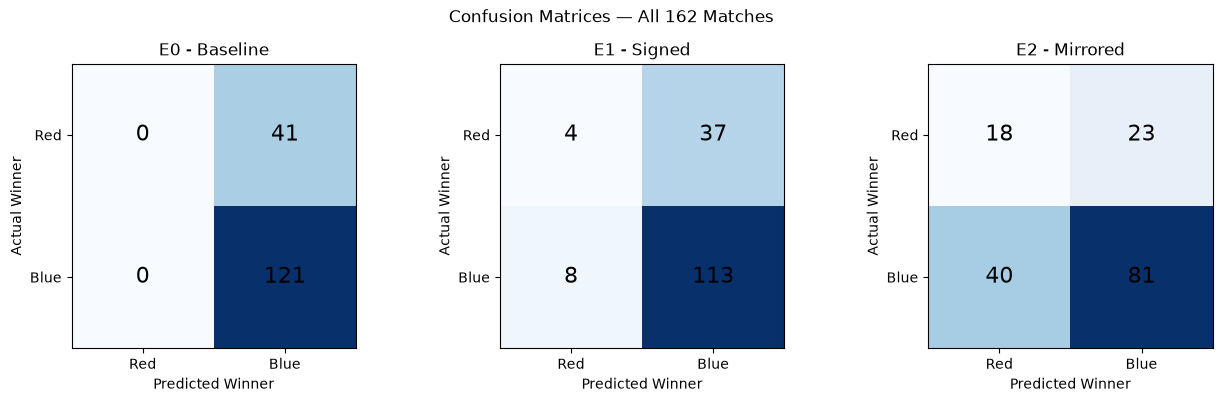

In [8]:
selected = [
    "E0_prior",
    "E1_original_signed",
    "E2_augmented_signed"
]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, name in zip(axes, selected):

    s = scores[name]

    matrix = [
        [s["TN"], s["FP"]],
        [s["FN"], s["TP"]]
    ]

    ax.imshow(matrix, cmap="Blues")

    for i in range(2):
        for j in range(2):
            ax.text(
                j, i, str(matrix[i][j]),
                ha="center", va="center",
                fontsize=16
            )

    ax.set_xticks([0, 1], ["Red", "Blue"])
    ax.set_yticks([0, 1], ["Red", "Blue"])

    ax.set_xlabel("Predicted Winner")
    ax.set_ylabel("Actual Winner")
    ax.set_title(labels[name])

plt.suptitle("Confusion Matrices — All 162 Matches")
plt.tight_layout()
plt.show()